<a href="https://colab.research.google.com/github/taniyasharma608093-debug/Loan-Approval-ML-Model/blob/main/loan_approval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import svm

In [4]:
df=pd.read_excel('/content/Copy of loan.xlsx')

In [5]:
#data cleaning

In [6]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [8]:
df.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


<Axes: >

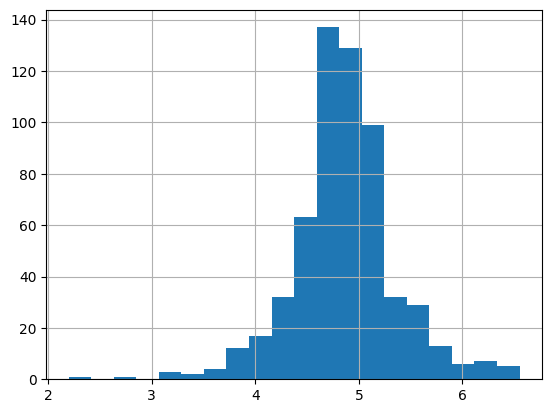

In [9]:
df['loanAmount_log'] = np.log(df['LoanAmount'])
df['loanAmount_log'].hist(bins=20)

In [43]:
df.shape

(614, 16)

In [10]:
df.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


<Axes: >

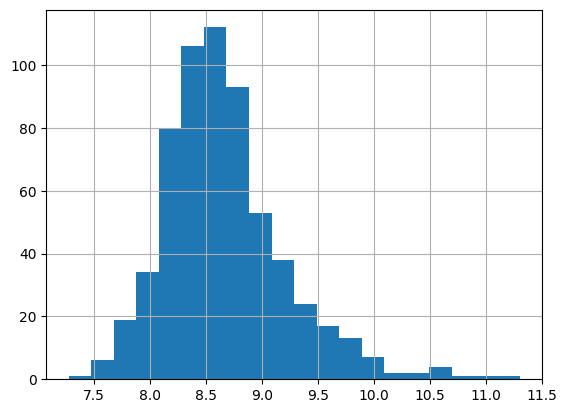

In [11]:
df['TotalIncome'] = df['ApplicantIncome'] + df['CoapplicantIncome']
df['TotalIncome_log'] = np.log(df['TotalIncome'])
df['TotalIncome_log'].hist(bins=20)

In [44]:
df['Gender'].fillna(df['Gender'].mode()[0],inplace=True)
df['Married'].fillna(df['Married'].mode()[0],inplace=True)
df['Self_Employed'].fillna(df['Self_Employed'].mode()[0],inplace=True)
df['Dependents'].fillna(df['Dependents'].mode()[0],inplace=True)


df.LoanAmount = df.LoanAmount.fillna(df.LoanAmount.mean())
df.loanAmount_log = df.loanAmount_log.fillna(df.loanAmount_log.mean())

df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0],inplace=True)
df['Credit_History'].fillna(df['Credit_History'].mode()[0],inplace=True)

df.isnull().sum()

/tmp/ipykernel_1057/3902661772.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Gender'].fillna(df['Gender'].mode()[0],inplace=True)
/tmp/ipykernel_1057/3902661772.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [13]:
x = df.iloc[:,np.r_[1:5,9:11,13:15]].values
y = df.iloc[:12].values

x

array([['Male', 'No', 0, ..., 1.0, 4.857444178729352, 5849.0],
       ['Male', 'Yes', 1, ..., 1.0, 4.852030263919617, 6091.0],
       ['Male', 'Yes', 0, ..., 1.0, 4.189654742026425, 3000.0],
       ...,
       ['Male', 'Yes', 1, ..., 1.0, 5.53338948872752, 8312.0],
       ['Male', 'Yes', 2, ..., 1.0, 5.231108616854587, 7583.0],
       ['Female', 'No', 0, ..., 0.0, 4.890349128221754, 4583.0]],
      dtype=object)

In [14]:
y

array([['LP001002', 'Male', 'No', 0, 'Graduate', 'No', 5849, 0.0,
        146.41216216216216, 360.0, 1.0, 'Urban', 'Y', 4.857444178729352,
        5849.0, 8.674025985443025],
       ['LP001003', 'Male', 'Yes', 1, 'Graduate', 'No', 4583, 1508.0,
        128.0, 360.0, 1.0, 'Rural', 'N', 4.852030263919617, 6091.0,
        8.714567550836485],
       ['LP001005', 'Male', 'Yes', 0, 'Graduate', 'Yes', 3000, 0.0, 66.0,
        360.0, 1.0, 'Urban', 'Y', 4.189654742026425, 3000.0,
        8.006367567650246],
       ['LP001006', 'Male', 'Yes', 0, 'Not Graduate', 'No', 2583, 2358.0,
        120.0, 360.0, 1.0, 'Urban', 'Y', 4.787491742782046, 4941.0,
        8.50532301884575],
       ['LP001008', 'Male', 'No', 0, 'Graduate', 'No', 6000, 0.0, 141.0,
        360.0, 1.0, 'Urban', 'Y', 4.948759890378168, 6000.0,
        8.699514748210191],
       ['LP001011', 'Male', 'Yes', 2, 'Graduate', 'Yes', 5417, 4196.0,
        267.0, 360.0, 1.0, 'Urban', 'Y', 5.58724865840025, 9613.0,
        9.170871628065816],

In [47]:
print("per of missing gender is %.2f%%" %((df['Gender'].isnull().sum() / df.shape[0])*100))

per of missing gender is 0.00%


number of people who take loan as group by gender:
Gender
Male      502
Female    112
Name: count, dtype: int64


/tmp/ipykernel_1057/1823122976.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Gender',data = df,palette='rainbow')


<Axes: xlabel='Gender', ylabel='count'>

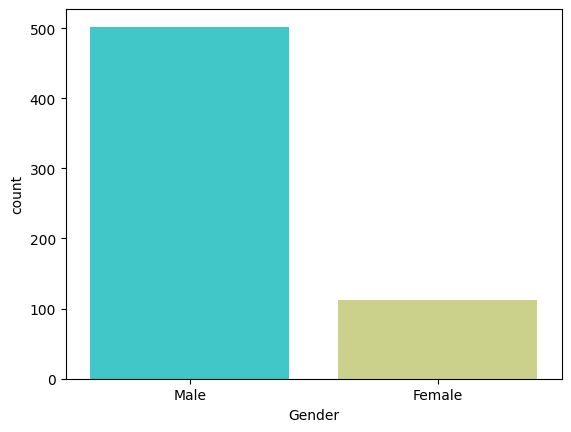

In [49]:
print("number of people who take loan as group by gender:")
print(df['Gender'].value_counts())
sns.countplot(x='Gender',data = df,palette='rainbow')

/tmp/ipykernel_1057/1410859845.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Married',data = df,palette='Set1')


number of people who take loan as group by marital status:
Married
Yes    401
No     213
Name: count, dtype: int64


<Axes: xlabel='Married', ylabel='count'>

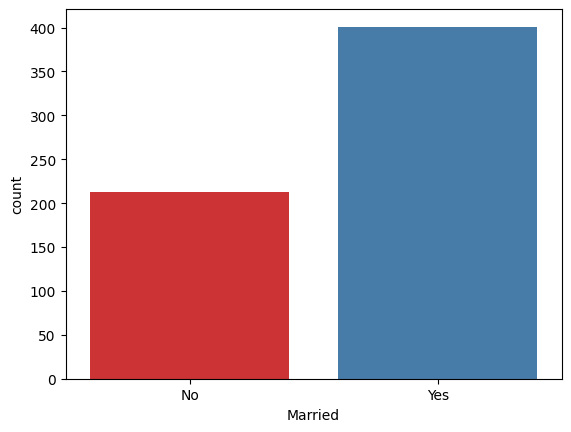

In [17]:
print("number of people who take loan as group by marital status:")
print(df['Married'].value_counts())
sns.countplot(x='Married',data = df,palette='Set1')

number of people who take loan as group by dependents:
Dependents
0     360
1     102
2     101
3+     51
Name: count, dtype: int64


/tmp/ipykernel_1057/2068659847.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Dependents',data = df,palette='Set1')


<Axes: xlabel='Dependents', ylabel='count'>

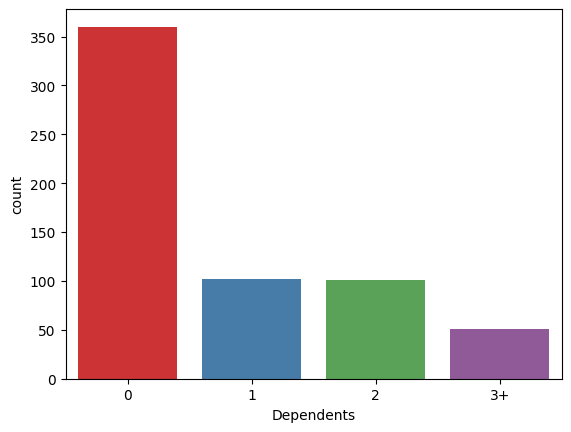

In [18]:
print("number of people who take loan as group by dependents:")
print(df['Dependents'].value_counts())
sns.countplot(x='Dependents',data = df,palette='Set1')

number of people who take loan as group by self employed:
Self_Employed
No     532
Yes     82
Name: count, dtype: int64


/tmp/ipykernel_1057/298916621.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Self_Employed',data = df,palette='Set1')


<Axes: xlabel='Self_Employed', ylabel='count'>

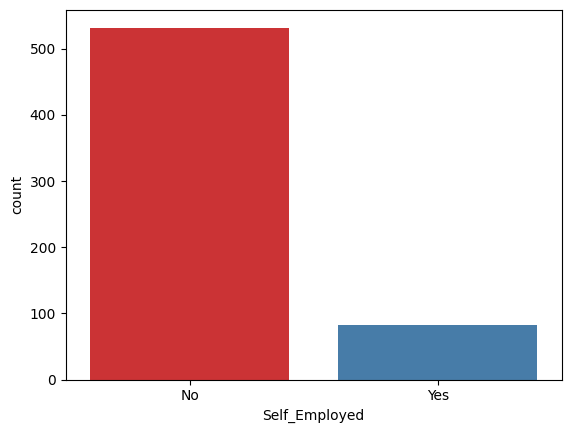

In [19]:
print("number of people who take loan as group by self employed:")
print(df['Self_Employed'].value_counts())
sns.countplot(x='Self_Employed',data = df,palette='Set1')

number of people who take loan as group by LoanAmount:
LoanAmount
146.412162    22
120.000000    20
110.000000    17
100.000000    15
187.000000    12
              ..
292.000000     1
142.000000     1
350.000000     1
496.000000     1
253.000000     1
Name: count, Length: 204, dtype: int64


/tmp/ipykernel_1057/1285420033.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='LoanAmount',data = df,palette='Set1')


<Axes: xlabel='LoanAmount', ylabel='count'>

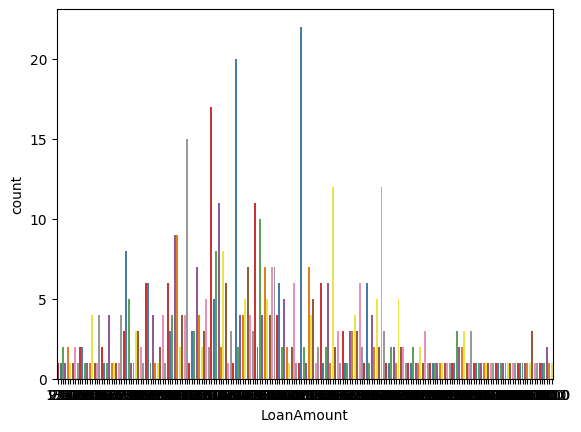

In [20]:
print("number of people who take loan as group by LoanAmount:")
print(df['LoanAmount'].value_counts())
sns.countplot(x='LoanAmount',data = df,palette='Set1')

number of people who take loan as group by Credit history:
Credit_History
1.0    525
0.0     89
Name: count, dtype: int64


/tmp/ipykernel_1057/1192888794.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Credit_History',data = df,palette='Set1')


<Axes: xlabel='Credit_History', ylabel='count'>

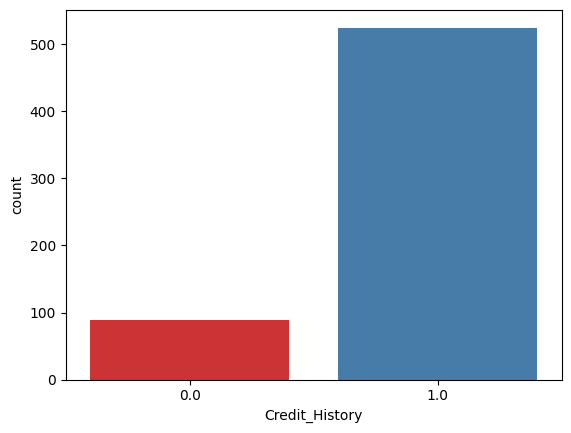

In [21]:
print("number of people who take loan as group by Credit history:")
print(df['Credit_History'].value_counts())
sns.countplot(x='Credit_History',data = df,palette='Set1')

In [22]:
print(x.shape)
print(y.shape)
print(len(x))
print(len(y))

x = df.drop('Loan_Status', axis=1)
y = df['Loan_Status']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=0)

from sklearn.preprocessing import LabelEncoder
Labelencoder_x = LabelEncoder()


(614, 8)
(12, 16)
614
12


In [23]:
from sklearn.preprocessing import LabelEncoder

Labelencoder_x = LabelEncoder()

for i in range(0, 5):
    X_train.iloc[:, i] = Labelencoder_x.fit_transform(
        X_train.iloc[:, i].astype(str)
    )

X_train.iloc[:, 7] = Labelencoder_x.fit_transform(
    X_train.iloc[:, 7].astype(str)
)

X_train

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,loanAmount_log,TotalIncome,TotalIncome_log
90,67,1,1,0,0,No,2958,149.0,131.0,360.0,1.0,Semiurban,4.875197,5858.0,8.675564
533,426,1,0,1,0,No,11250,0.0,196.0,360.0,1.0,Semiurban,5.278115,11250.0,9.328123
452,360,1,1,0,0,No,3948,54.0,149.0,360.0,0.0,Rural,5.003946,5681.0,8.644883
355,287,0,0,0,0,No,3813,0.0,116.0,180.0,1.0,Urban,4.753590,3813.0,8.246172
266,210,1,1,2,0,No,4708,25.0,150.0,360.0,1.0,Semiurban,5.010635,6095.0,8.715224
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277,220,1,1,0,0,No,3103,21.0,80.0,360.0,1.0,Urban,4.382027,4403.0,8.390041
9,6,1,1,1,0,No,12841,9.0,349.0,360.0,1.0,Semiurban,5.855072,23809.0,10.077819
359,289,1,1,3,0,No,5167,161.0,200.0,360.0,1.0,Semiurban,5.298317,8334.0,9.028099
192,156,1,1,0,1,No,6033,0.0,160.0,360.0,1.0,Urban,5.075174,6033.0,8.705000


In [24]:
Labelencoder_y = LabelEncoder()
y_train = Labelencoder_y.fit_transform(y_train)
y_train


array([1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1,

In [25]:
from sklearn.preprocessing import LabelEncoder

for i in range(0, 5):
    X_train.iloc[:, i] = X_train.iloc[:, i].astype(str)
    X_test.iloc[:, i] = X_test.iloc[:, i].astype(str)

    Labelencoder_x = LabelEncoder()
    X_train.iloc[:, i] = Labelencoder_x.fit_transform(X_train.iloc[:, i])

    X_test.iloc[:, i] = X_test.iloc[:, i].map(
        lambda value: Labelencoder_x.transform([value])[0]
        if value in Labelencoder_x.classes_ else -1
    )

X_train.iloc[:, 7] = X_train.iloc[:, 7].astype(str)
X_test.iloc[:, 7] = X_test.iloc[:, 7].astype(str)

Labelencoder_x = LabelEncoder()
X_train.iloc[:, 7] = Labelencoder_x.fit_transform(X_train.iloc[:, 7])

X_test.iloc[:, 7] = X_test.iloc[:, 7].map(
    lambda value: Labelencoder_x.transform([value])[0]
    if value in Labelencoder_x.classes_ else -1
)

X_test

/tmp/ipykernel_1057/3464051552.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '90     149.0
533      0.0
452     54.0
355      0.0
266     25.0
       ...  
277     21.0
9        9.0
359    161.0
192      0.0
559    117.0
Name: CoapplicantIncome, Length: 491, dtype: object' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  X_train.iloc[:, 7] = X_train.iloc[:, 7].astype(str)
/tmp/ipykernel_1057/3464051552.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '454       0.0
52        0.0
536    3906.0
469    2451.0
55     1167.0
        ...  
337    4600.0
376    4996.0
278       0.0
466    1664.0
303    1803.0
Name: CoapplicantIncome, Length: 123, dtype: object' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  X_test.iloc[:, 7] = X_test.iloc[:, 7].astype(str)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,loanAmount_log,TotalIncome,TotalIncome_log
454,-1,-1,-1,0,-1,Yes,7085,0,84.0,360.0,1.0,Semiurban,4.430817,7085.0,8.865735
52,-1,-1,-1,0,-1,No,4230,0,112.0,360.0,1.0,Semiurban,4.718499,4230.0,8.349957
536,-1,-1,-1,0,-1,No,6133,-1,324.0,360.0,1.0,Urban,5.780744,10039.0,9.214233
469,-1,-1,-1,0,-1,No,4333,-1,110.0,360.0,1.0,Urban,4.700480,6784.0,8.822322
55,-1,-1,-1,2,-1,No,2708,-1,97.0,360.0,1.0,Semiurban,4.574711,3875.0,8.262301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337,-1,-1,-1,2,-1,Yes,2500,-1,176.0,360.0,1.0,Rural,5.170484,7100.0,8.867850
376,-1,-1,-1,-1,-1,No,8750,-1,130.0,360.0,1.0,Rural,4.867534,13746.0,9.528503
278,-1,-1,-1,0,-1,No,14583,0,436.0,360.0,1.0,Semiurban,6.077642,14583.0,9.587612
466,-1,-1,-1,-1,-1,No,2947,-1,70.0,180.0,0.0,Urban,4.248495,4611.0,8.436200


In [26]:
Labelencoder_y = LabelEncoder()
y_test = Labelencoder_y.fit_transform(y_test)
y_test

array([1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1])

In [27]:
# First split the original data
from sklearn.model_selection import train_test_split

x = df.drop(columns=['Loan_Status', 'Loan_ID'])
y = df['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Encode categorical columns consistently
import pandas as pd

X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

X_train, X_test = X_train.align(
    X_test, join='left', axis=1, fill_value=0
)

# Scale the data
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_test = ss.transform(X_test)

In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier()
rf_clf.fit(X_train, y_train)

RandomForestClassifier()

In [29]:
from sklearn import metrics
y_pred = rf_clf.predict(X_test)

print("acc of random forest clf is" , metrics.accuracy_score(y_pred,y_test))

y_pred

acc of random forest clf is 0.7967479674796748


array(['Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'N', 'Y', 'N', 'Y', 'Y', 'N', 'Y', 'Y', 'N', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'N', 'Y',
       'Y', 'Y', 'Y', 'Y', 'N', 'Y'], dtype=object)

In [30]:
from sklearn.naive_bayes import GaussianNB

nb_clf = GaussianNB()
nb_clf.fit(X_train, y_train)

GaussianNB()

In [31]:
y_pred = nb_clf.predict(X_test)
print("acc of naive bayes is ",metrics.accuracy_score(y_pred,y_test))

acc of naive bayes is  0.8292682926829268


In [32]:
y_pred


array(['Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'N', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y',
       'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'N', 'Y',
       'Y', 'Y', 'Y', 'Y', 'N', 'Y'], dtype='<U1')

In [33]:
from sklearn.tree import DecisionTreeClassifier

dt_clf = DecisionTreeClassifier()
dt_clf.fit(X_train, y_train)

DecisionTreeClassifier()

In [34]:
y_pred = dt_clf.predict(X_test)
print("acc of decision tree is ",metrics.accuracy_score(y_pred,y_test))

acc of decision tree is  0.7317073170731707


In [35]:
y_pred

array(['Y', 'Y', 'N', 'Y', 'Y', 'Y', 'N', 'Y', 'N', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'N', 'Y', 'N', 'N', 'N', 'Y', 'N', 'Y', 'Y', 'Y',
       'N', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'N', 'N', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y',
       'Y', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'N', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y',
       'Y', 'N', 'N', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'N', 'N',
       'Y', 'Y', 'Y', 'N', 'Y', 'N', 'Y', 'N', 'Y', 'Y', 'N', 'N', 'Y',
       'Y', 'N', 'Y', 'N', 'N', 'Y'], dtype=object)

In [36]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_train)

KNeighborsClassifier()

In [37]:
y_pred = knn_clf.predict(X_test)
print("acc of knn is ",metrics.accuracy_score(y_pred,y_test))


acc of knn is  0.7560975609756098


In [38]:
y_pred

array(['Y', 'Y', 'N', 'Y', 'Y', 'N', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'N', 'Y', 'Y', 'Y', 'Y', 'Y',
       'N', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'Y', 'N', 'N', 'Y',
       'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'N', 'Y', 'Y', 'Y', 'N', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N', 'N', 'Y',
       'Y', 'Y', 'Y', 'N', 'N', 'Y'], dtype=object)

### Step 1: Install Streamlit and Localtunnel
To run the application, we need to install `streamlit` and `localtunnel` so we can access the web interface from Colab.

In [55]:
!pip install -q streamlit
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦
changed 22 packages in 2s
⠦
⠦3 packages are looking for funding
⠦  run `npm fund` for details
⠦

### Step 2: Save the Trained Model and Preprocessing Components
For our Streamlit application to make predictions, it needs to access the model (`nb_clf`) and the preprocessing components (like our feature schema or scale metrics). Let's save our model and preprocessing components to disk using `pickle`.

In [56]:
import pickle

# Save the best model (Naive Bayes)
with open('best_model.pkl', 'wb') as f:
    pickle.dump(nb_clf, f)

# Save the scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(ss, f)

# Save the column structure of the aligned features
model_columns = list(pd.get_dummies(df.drop(columns=['Loan_Status', 'Loan_ID'])).columns)
with open('model_columns.pkl', 'wb') as f:
    pickle.dump(model_columns, f)

### Step 3: Write the Streamlit Web Application
We write the application code into a file called `app.py`. This script reads user inputs, formats them exactly as the model expects, processes them with our saved scaler, and returns predictions.

In [57]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import pickle

# Load components
with open('best_model.pkl', 'rb') as f:
    model = pickle.load(f)
with open('scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)
with open('model_columns.pkl', 'rb') as f:
    model_columns = pickle.load(f)

st.set_page_config(page_title="Loan Eligibility Predictor", layout="centered")
st.title("🏦 Loan Eligibility Prediction Portal")

# Input fields
with st.form("loan_form"):
    gender = st.selectbox("Gender", ["Male", "Female"])
    married = st.selectbox("Married", ["Yes", "No"])
    dependents = st.selectbox("Dependents", ["0", "1", "2", "3+"])
    education = st.selectbox("Education", ["Graduate", "Not Graduate"])
    self_employed = st.selectbox("Self Employed", ["Yes", "No"])
    applicant_income = st.number_input("Applicant Income", min_value=0, value=5000)
    coapplicant_income = st.number_input("Coapplicant Income", min_value=0, value=0)
    loan_amount = st.number_input("Loan Amount (Thousands)", min_value=0, value=150)
    loan_amount_term = st.number_input("Loan Amount Term (Days)", min_value=0, value=360)
    credit_history = st.selectbox("Credit History", [1.0, 0.0])
    property_area = st.selectbox("Property Area", ["Urban", "Semiurban", "Rural"])

    submit = st.form_submit_button("Predict Eligibility")

if submit:
    # Feature Engineering matching training notebook logic
    total_income = applicant_income + coapplicant_income
    total_income_log = np.log(total_income) if total_income > 0 else 0
    loan_amount_log = np.log(loan_amount) if loan_amount > 0 else 0

    # Raw input dataframe
    raw_input = pd.DataFrame([{
        'Gender': gender,
        'Married': married,
        'Dependents': dependents,
        'Education': education,
        'Self_Employed': self_employed,
        'ApplicantIncome': applicant_income,
        'CoapplicantIncome': coapplicant_income,
        'LoanAmount': loan_amount,
        'Loan_Amount_Term': loan_amount_term,
        'Credit_History': credit_history,
        'Property_Area': property_area,
        'loanAmount_log': loan_amount_log,
        'TotalIncome': total_income,
        'TotalIncome_log': total_income_log
    }])

    # Encode categorical columns consistently with get_dummies
    encoded_input = pd.get_dummies(raw_input)

    # Align with training columns
    for col in model_columns:
        if col not in encoded_input.columns:
            encoded_input[col] = 0
    encoded_input = encoded_input[model_columns]

    # Scale data
    scaled_input = scaler.transform(encoded_input)

    # Predict
    prediction = model.predict(scaled_input)[0]

    if prediction == 'Y':
        st.success("Congratulations! The applicant is predicted ELIGIBLE for the loan. 🎉")
    else:
        st.error("The applicant is predicted NOT ELIGIBLE for the loan. ❌")

Overwriting app.py


### Step 4: Run the App and Launch the Tunnel
We request your public IP password to authenticate localtunnel, start the web server in the background, and output the interactive link.

In [58]:
# Fetch the password needed for the localtunnel verification page
!curl ipv4.icanhazip.com

34.60.68.236


In [ ]:
import subprocess
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501"])
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧your url is: https://cuddly-animals-prove.loca.lt
